# Install required libraries

In [1]:
!pip install torch torchvision matplotlib

# Load MNIST Dataset

In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

# Use GPU if available
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)

# Convert images to tensors and normalize to [-1, 1]
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

# Download MNIST
dataset = torchvision.datasets.MNIST(
    root="./data",
    train=True,
    transform=transform,
    download=True
)

# Load images in batches
dataloader = torch.utils.data.DataLoader(
    dataset,
    batch_size=128,
    shuffle=True,
    drop_last=True
)

print("Training images:", len(dataset))

Using device: cuda


100%|██████████| 9.91M/9.91M [00:00<00:00, 20.6MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 499kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.01MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 7.98MB/s]

Training images: 60000


# Build the Generator

In [3]:
class Generator(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            # 1 x 1 -> 7 x 7
            nn.ConvTranspose2d(
                100, 128, kernel_size=7
            ),
            nn.BatchNorm2d(128),
            nn.ReLU(True),

            # 7 x 7 -> 14 x 14
            nn.ConvTranspose2d(
                128, 64, kernel_size=4,
                stride=2, padding=1
            ),
            nn.BatchNorm2d(64),
            nn.ReLU(True),

            # 14 x 14 -> 28 x 28
            nn.ConvTranspose2d(
                64, 1, kernel_size=4,
                stride=2, padding=1
            ),
            nn.Tanh()
        )

    def forward(self, z):
        return self.network(z)


generator = Generator().to(device)

print(generator)

Generator(
  (network): Sequential(
    (0): ConvTranspose2d(100, 128, kernel_size=(7, 7), stride=(1, 1))
    (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): ConvTranspose2d(128, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): ConvTranspose2d(64, 1, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (7): Tanh()
  )
)


# Build the Discriminator

In [4]:
class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            # 28 x 28 -> 14 x 14
            nn.Conv2d(
                1, 64, kernel_size=4,
                stride=2, padding=1
            ),
            nn.LeakyReLU(0.2, inplace=True),

            # 14 x 14 -> 7 x 7
            nn.Conv2d(
                64, 128, kernel_size=4,
                stride=2, padding=1
            ),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),

            # 7 x 7 -> 1 x 1
            nn.Conv2d(
                128, 1, kernel_size=7
            )
        )

    def forward(self, image):
        return self.network(image).view(-1)


discriminator = Discriminator().to(device)

print(discriminator)

Discriminator(
  (network): Sequential(
    (0): Conv2d(1, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): LeakyReLU(negative_slope=0.2, inplace=True)
    (2): Conv2d(64, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (3): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (4): LeakyReLU(negative_slope=0.2, inplace=True)
    (5): Conv2d(128, 1, kernel_size=(7, 7), stride=(1, 1))
  )
)


# Define the loss functions and optimizers

In [5]:
# Loss function for real/fake classification
criterion = nn.BCEWithLogitsLoss()

# Separate optimizers for the two networks
optimizer_G = optim.Adam(
    generator.parameters(),
    lr=0.0002,
    betas=(0.5, 0.999)
)

optimizer_D = optim.Adam(
    discriminator.parameters(),
    lr=0.0002,
    betas=(0.5, 0.999)
)

# Train the DCGAN

In [6]:
num_epochs = 10
latent_dim = 100

for epoch in range(num_epochs):

    for real_images, _ in dataloader:
        real_images = real_images.to(device)
        batch_size = real_images.size(0)

        # Labels for real and fake images
        real_labels = torch.ones(batch_size, device=device)
        fake_labels = torch.zeros(batch_size, device=device)

        # --------------------------------
        # Step 1: Train the Discriminator
        # --------------------------------
        optimizer_D.zero_grad()

        # Classify real images
        real_output = discriminator(real_images)
        loss_real = criterion(real_output, real_labels)

        # Generate fake images
        noise = torch.randn(
            batch_size, latent_dim, 1, 1, device=device
        )
        fake_images = generator(noise)

        # Classify fake images
        fake_output = discriminator(fake_images.detach())
        loss_fake = criterion(fake_output, fake_labels)

        # Combine real and fake losses
        loss_D = loss_real + loss_fake
        loss_D.backward()
        optimizer_D.step()

        # ----------------------------
        # Step 2: Train the Generator
        # ----------------------------
        optimizer_G.zero_grad()

        # Generate new fake images
        noise = torch.randn(
            batch_size, latent_dim, 1, 1, device=device
        )
        fake_images = generator(noise)

        # Generator wants fake images to look real
        output = discriminator(fake_images)
        loss_G = criterion(output, real_labels)

        loss_G.backward()
        optimizer_G.step()

    print(
        f"Epoch [{epoch + 1}/{num_epochs}] "
        f"Loss D: {loss_D.item():.4f} "
        f"Loss G: {loss_G.item():.4f}"
    )

Epoch [1/10] Loss D: 0.5967 Loss G: 1.4243
Epoch [2/10] Loss D: 0.4791 Loss G: 1.9415
Epoch [3/10] Loss D: 0.5257 Loss G: 2.0455
Epoch [4/10] Loss D: 0.5617 Loss G: 1.8263
Epoch [5/10] Loss D: 0.5932 Loss G: 1.8195
Epoch [6/10] Loss D: 0.6515 Loss G: 1.4279
Epoch [7/10] Loss D: 0.6571 Loss G: 2.1486
Epoch [8/10] Loss D: 0.6176 Loss G: 1.6662
Epoch [9/10] Loss D: 1.0103 Loss G: 2.7934
Epoch [10/10] Loss D: 0.7251 Loss G: 2.9221


# Generate and display new images

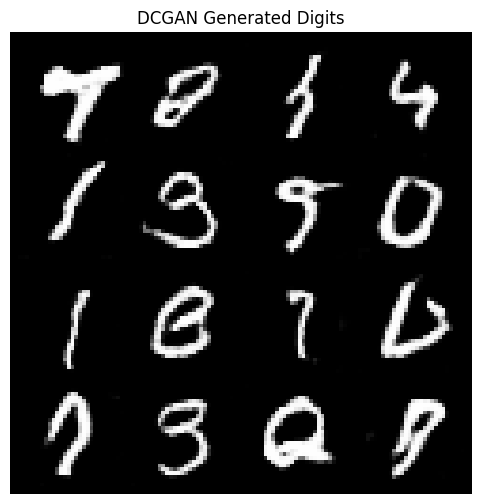

In [9]:

import torchvision.utils as vutils
import matplotlib.pyplot as plt
import torch

generator.eval()

# Generate 16 images
with torch.no_grad():
    noise = torch.randn(16, 100, 1, 1, device=device)
    generated_images = generator(noise).cpu()

# Create a grid of generated images
grid = vutils.make_grid(
    generated_images,
    nrow=4,
    normalize=True,
    value_range=(-1, 1),
    padding=2
)

# Convert from (C, H, W) to (H, W, C)
grid = grid.permute(1, 2, 0).numpy()

# Display the images
plt.figure(figsize=(6, 6))
plt.imshow(grid, cmap="gray")
plt.axis("off")
plt.title("DCGAN Generated Digits")
plt.show()

# Save your trained model

In [10]:
torch.save(
    generator.state_dict(),
    "dcgn_generator.pth"
)

print("Generator saved sucessfully!")

Generator saved sucessfully!


In [12]:
generator = Generator().to(device)

generator.load_state_dict(
    torch.load(
        "/content/dcgn_generator.pth",
        map_location=device,
        weights_only=True
    )
)

generator.eval()

Generator(
  (network): Sequential(
    (0): ConvTranspose2d(100, 128, kernel_size=(7, 7), stride=(1, 1))
    (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): ConvTranspose2d(128, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): ConvTranspose2d(64, 1, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (7): Tanh()
  )
)